<a id="chapter-13"></a>

# Chapter 13 · The TextWorld Environment / 文本世界

[← 学习索引](README.md) · [项目主页](../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 把文本游戏理解为部分可观测问题
- 处理 token、命令与动作掩码
- 理解文本状态的 DQN/Transformer 表示

**开始前最好已经会：**

- 理解 POMDP 的直觉
- 知道 token、embedding 和 sequence
- 掌握动作价值或策略输出


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Interactive fiction / environment | POMDP 与 TextWorld | 详细 |
| Deep NLP basics | token、embedding、序列模型 | 详细 |
| Baseline DQN | 文本编码到动作价值 | 完整流程 |
| Tweaking observations | 预处理与状态信息 | 详细 |
| Transformers | 预训练编码器源码路线 | 结构理解 |
| ChatGPT | 交互/自动 agent 入口 | 应用与限制 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

看到‘你在厨房里’，智能体还需要记住刚才拿过钥匙吗？文本游戏把语言理解、记忆和决策压缩进同一个任务。

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

观测是文本，动作也是命令；同一句话的顺序和历史可能重要。可行命令集合提供 action mask，避免在大量无效动作上浪费探索。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $O_t$ | 当前文本观测 | 可能不包含完整世界状态 |
| $H_t$ | 交互历史 | 观测与动作序列 |
| $z_t$ | 历史的向量表示 | RNN/Transformer/池化结果 |
| $m_a$ | 合法动作 mask | 1 合法、0 非法 |
| vocabulary | token 到整数的映射 | 决定模型输入 id |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 为什么当前文本不一定是 Markov 状态

相同房间描述可能对应“钥匙已经拿走”和“钥匙仍在桌上”两种隐藏状态。若观测不足，应让表示依赖历史：

$$z_t=f_\theta(O_1,A_1,\ldots,O_t)$$

然后估计 $Q(z_t,a)$ 或 $\pi(a|z_t)$。简单任务可拼接最近若干观测，长依赖更适合 recurrent/attention 模型。

### 2. token 怎样进入网络

文本经过 tokenizer 得到 id 序列 $(i_1,\ldots,i_L)$，embedding 查表得到向量，再池化或编码：

$$e_j=E[i_j],\qquad z=\operatorname{Encoder}(e_1,\ldots,e_L)$$

padding 只是凑 batch 长度，必须用 attention mask 排除。

### 3. action mask 为什么在 logits 上操作

令非法动作 logit 为 $-\infty$：

$$\tilde z_a=\begin{cases}z_a&m_a=1\\-\infty&m_a=0\end{cases}$$

softmax 后 $e^{-\infty}=0$，非法动作概率严格为零。事后把概率乘 0 再归一化也能做，但 logits mask 更稳定、实现更直接。


## 4. 手算一个最小例子


logits `[2,1,3,-1]`，只有动作 0、2 合法。mask 后为 `[2,-∞,3,-∞]`。合法动作 softmax 概率约为 `[0.269,0.731]`，非法动作均为 0。

注意：mask 不能把所有动作都屏蔽，否则 softmax 会产生 NaN。数据管线应断言每个状态至少有一个合法动作。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### POMDP 与动作掩码

历史 $h_t=(o_1,a_1,\ldots,o_t)$ 可编码为隐藏状态 $z_t=f_\theta(h_t)$，再估计 $Q(z_t,a)$。

若合法动作掩码 $m_a\in\{0,1\}$，可在 softmax 前设
$$\tilde z_a=\begin{cases}z_a&m_a=1\\-\infty&m_a=0\end{cases}$$
从而使非法动作概率为 0。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| 文本 $O_t$ | `observation` | 原始字符串 |
| token 序列 | `tokens = tokenize(observation)` | 规范化后的词元 |
| token id | `vocab[word]` | embedding 的整数索引 |
| $z_a$ | `logits`，shape `(num_actions,)` | 每个候选命令分数 |
| $m_a$ | `legal` bool tensor | 合法命令位置 |
| $-\infty$ mask | `masked_fill(~legal, -torch.inf)` | softmax 前屏蔽 |

**从公式过渡到代码时：**这里用简化 tokenizer 和 masked softmax 解释数据流；项目脚本负责真实 TextWorld/Hugging Face 集成。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import re
import torch

def tokenize(text):
    return re.findall(r"[a-z']+", text.lower())

observation = "You are in a kitchen. A red key is on the table."
tokens = tokenize(observation)
vocab = {word: i + 1 for i, word in enumerate(sorted(set(tokens)))}
token_ids = torch.tensor([vocab[w] for w in tokens])
print("tokens:", tokens)
print("ids:", token_ids.tolist())

logits = torch.tensor([2.0, 1.0, 3.0, -1.0])
legal = torch.tensor([True, False, True, False])
masked_logits = logits.masked_fill(~legal, -torch.inf)
print("masked probabilities:", torch.softmax(masked_logits, dim=0))


tokens: ['you', 'are', 'in', 'a', 'kitchen', 'a', 'red', 'key', 'is', 'on', 'the', 'table']
ids: [11, 2, 3, 1, 6, 1, 8, 5, 4, 7, 10, 9]
masked probabilities: tensor([0.2689, 0.0000, 0.7311, 0.0000])


### 怎样读运行结果

示例 tokenizer 故意简单，只讲数据形状。真实项目的 preprocessing、预训练编码器和 action candidates 分别查看链接文件，不要把示例 tokenizer 当成生产方案。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
TextWorld reset → textual observation + admissible commands
preprocessor:
  normalize text → tokenize → ids → pad/mask
model:
  embedding/encoder → state vector
  对候选动作编码或输出固定动作 Q/logits
用 legal-action mask 排除不可执行命令
DQN/策略方法选择命令并 step
把文本、候选命令、所选命令、reward 一起记录到 replay
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import torch

# 带 padding mask 的平均池化；padding id 对表示不应有贡献。
emb = torch.tensor([[[1., 0.], [3., 2.], [99., 99.]]])
mask = torch.tensor([[1., 1., 0.]])
pooled = (emb * mask[..., None]).sum(1) / mask.sum(1, keepdim=True)
print("masked mean:", pooled)
assert torch.allclose(pooled, torch.tensor([[2., 1.]]))


masked mean: tensor([[2., 1.]])


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`preproc.py`](../Chapter13/lib/preproc.py) | tokenization / preprocessing | 先看文本怎样变 tensor |
| [`model.py`](../Chapter13/lib/model.py) | 文本模型 | 跟踪 embedding、hidden、动作输出 shape |
| [`train_basic.py`](../Chapter13/train_basic.py) | baseline DQN | 完整交互和 replay |
| [`train_preproc.py`](../Chapter13/train_preproc.py) | 改进 observation | 比较输入信息 |
| [`train_tr.py`](../Chapter13/train_tr.py) | transformer 版本 | 预训练编码器接入 |
| [`test_preproc.py`](../Chapter13/tests/test_preproc.py) | 预处理测试 | 边界与 padding 的规范 |
| [`chatgpt_interactive.py`](../Chapter13/chatgpt_interactive.py) | 交互式 agent | 提示、状态与外部模型边界 |

<details>
<summary>为什么按这个顺序读</summary>

先读 `test_preproc.py` 再读预处理实现，确认大小写、未知词、padding 和长度截断。随后画出 model 输入 shape：`(batch, seq_len)` ids → embedding `(batch, seq_len, dim)` → mask pooling/encoder → Q/logits。Transformer 版的主要变化是表示层，不改变 RL transition。ChatGPT 入口依赖外部服务，应把响应失败、成本、非确定性与安全边界当作环境工程问题。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**简化文本 observation 分类器的交叉熵

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


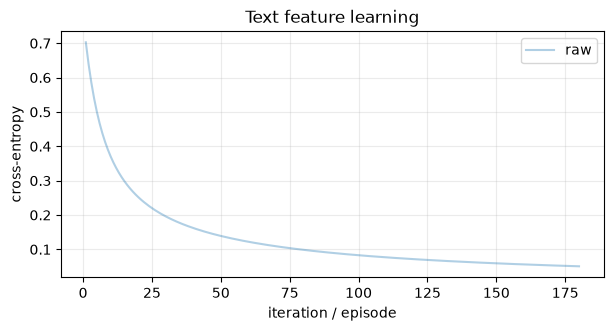

predictions: [0 1 1 0 1 0] targets: [0 1 1 0 1 0]


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(13)
# 词袋特征：[door, key, monster, treasure]；目标是选择 explore(0) / take(1)。
x = np.array([[1,0,0,0], [1,1,0,0], [0,1,0,1], [0,0,1,0], [0,0,0,1], [1,0,1,0]], float)
y = np.array([0,1,1,0,1,0])
w = rng.normal(0, .1, (4, 2)); losses = []
for _ in range(180):
    logits = x @ w; logits -= logits.max(axis=1, keepdims=True)
    probs = np.exp(logits); probs /= probs.sum(axis=1, keepdims=True)
    loss = -np.log(probs[np.arange(len(y)), y] + 1e-9).mean(); losses.append(loss)
    grad = x.T @ (probs - np.eye(2)[y]) / len(y)
    w -= .35 * grad

plot_curve(losses, "Text feature learning", "cross-entropy")
print("predictions:", (x @ w).argmax(axis=1), "targets:", y)


### 曲线怎么读

loss 下降且训练预测正确，只说明表示能拟合这个小数据集；TextWorld 中还必须看任务完成率和未见游戏泛化，不能把语言模型 loss 当成 RL 成功。

### 调参过程：一次只改变一个因素

- 先固定游戏集合和 tokenizer，建立随机/规则 baseline。
- 比较原始文本、结构化实体特征和 transformer 表示，保持 RL 预算相同。
- 在未见 seed/游戏上选模型，防止记住房间描述。

### 失败案例复盘

- 词表在测试数据上拟合，泄漏未见文本信息。
- padding mask 错误，模型主要学习序列长度。
- 训练 loss 很低但 agent 没有探索到完成任务的轨迹。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 缓存 tokenizer 输出能明显减少训练开销。
- padding token 必须在 attention/pooling 中正确屏蔽。
- 记录原始文本、可行动作与所选动作，比只记录 reward 更容易调试。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

给 logits 增加第五个动作并设为非法；验证无论 logit 多大，其概率仍为 0。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

新增第五个动作并将其 mask 设为 False，即使 logit=100，`masked_fill(~legal, -inf)` 后概率仍为 0。还应增加 `assert legal.any()`，避免所有动作非法导致 softmax NaN。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- 文本观测往往是部分可观测的，需要历史。
- tokenizer、padding mask 和 action mask 都属于算法输入定义。
- 非法动作应在采样前屏蔽。
- 先保证小词表/小模型的数据管线正确，再接预训练模型。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**padding mask 和 action mask 分别屏蔽什么？为什么不能让一个状态的所有 action 都非法？

<details>
<summary>展开答案</summary>

padding mask 屏蔽序列中补齐位置，action mask 屏蔽当前状态不可执行的命令。全非法会让 softmax 分母为零等价情形，产生 NaN。
</details>


## 17. 与前后章节连接

第 14 章把语言与视觉/DOM 结合到网页环境；共同难点仍是部分可观测、动作候选和昂贵交互。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

可用 pretrained language model 编码状态，但环境交互成本、上下文长度与微调稳定性会成为新瓶颈。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-13) · [← 学习索引](README.md)
